<a href="https://colab.research.google.com/github/Savithmee/Deep-Learning-CW-/blob/Sahanmee/EntailmentPreprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install spacy nltk psutil
import nltk
nltk.download('punkt_tab', quiet=True); nltk.download('punkt', quiet=True)

True

In [2]:
import os, json
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/Deep Learning Coursework'
PASSAGES = f'{DATA_DIR}/passages_bm25_ChatGPT_humfacts.jsonl'
LABELS   = f'{DATA_DIR}/dev_labeled_ChatGPT.jsonl'

# quick check that both files are found
print(os.listdir(DATA_DIR))
assert os.path.exists(PASSAGES), 'passages file not found, check the name in the list above'
assert os.path.exists(LABELS),   'labels file not found, check the name in the list above'

Mounted at /content/drive
['dev_labeled_ChatGPT.jsonl', 'passages_bm25_ChatGPT_humfacts.jsonl']


In [3]:
%%writefile preprocessing.py
import re, html, unicodedata
from typing import List, Dict, Optional

STOPWORDS = set("""a about above after again against all am an and any are as at be because been before being
below between both but by can did do does doing down during each few for from further had has have having he her
here hers herself him himself his how i if in into is it its itself just me more most my myself no nor not now of
off on once only or other our ours ourselves out over own same she should so some such than that the their theirs
them themselves then there these they this those through to too under until up very was we were what when where
which while who whom why will with you your yours yourself yourselves also""".split())

DEFAULT_CFG = dict(
    splitter="regex",        # tags | naive | regex | nltk | spacy
    min_words=3,
    max_words=100,
    window=1,                # 1 = single sentences, 2/3 = windows, 10**6 = whole passage
    stride=1,
    title="none",            # none | all | pronoun
    prune_thr=None,          # None = no pruning
    min_keep=1,
    max_keep=None,
    order="window_then_prune",   # or prune_then_window
)

# cleaning
_TAG = re.compile(r"<[^>]+>")
_CITE = re.compile(r"\[\d+\]|\[citation needed\]", re.I)

def clean_text(text: str, title: Optional[str] = None) -> str:
    t = html.unescape(text)
    t = unicodedata.normalize("NFKC", t)
    t = _CITE.sub(" ", t)
    t = _TAG.sub(" ", t)
    t = re.sub(r"\s+", " ", t).strip()
    if title and t.startswith(title + " " + title):
        t = t[len(title) + 1:]
    return t

# sentence splitting
_REGEX_SPLIT = re.compile(r"(?<=[.!?])\s+(?=[\"'(A-Z0-9])")
_SPACY = None
_NLTK_OK = None

def _split_text(segments: List[str], splitter: str) -> List[str]:
    global _SPACY, _NLTK_OK
    if splitter == "tags":
        return segments
    out = []
    if splitter == "naive":
        for s in segments:
            parts = s.split(". ")
            out += [p if p.endswith(".") or i == len(parts) - 1 else p + "." for i, p in enumerate(parts)]
    elif splitter == "regex":
        for s in segments:
            out += _REGEX_SPLIT.split(s)
    elif splitter == "nltk":
        import nltk
        from nltk.tokenize import sent_tokenize
        if _NLTK_OK is None:
            nltk.download("punkt_tab", quiet=True)
            nltk.download("punkt", quiet=True)
            _NLTK_OK = True
        for s in segments:
            out += sent_tokenize(s)
    elif splitter == "spacy":
        if _SPACY is None:
            import spacy
            _SPACY = spacy.blank("en")
            _SPACY.add_pipe("sentencizer")
        for doc in _SPACY.pipe(segments):
            out += [x.text for x in doc.sents]
    else:
        raise ValueError("unknown splitter " + splitter)
    return out

def _chunk(text: str, max_words: Optional[int]) -> List[str]:
    words = text.split()
    if not max_words or len(words) <= max_words:
        return [text]
    pieces, cur = [], []
    for part in re.split(r"(?<=;)\s+", text):
        pw = part.split()
        if cur and len(cur) + len(pw) > max_words:
            pieces.append(" ".join(cur)); cur = []
        cur += pw
    if cur:
        pieces.append(" ".join(cur))
    out = []
    for p in pieces:
        w = p.split()
        out += [" ".join(w[i:i + max_words]) for i in range(0, len(w), max_words)]
    return out

def sentence_units(passages: List[dict], splitter="regex", min_words=3, max_words=100) -> List[Dict]:
    units, seen = [], set()
    for pid, p in enumerate(passages):
        title = p.get("title", "")
        segs = [clean_text(s, title) for s in re.split(r"</?s>", p["text"])]
        segs = [s for s in segs if s]
        sid = 0
        for sent in _split_text(segs, splitter):
            for piece in _chunk(sent.strip(), max_words):
                if len(piece.split()) < min_words:
                    continue
                key = piece.lower()
                if key in seen:
                    continue
                seen.add(key)
                units.append(dict(title=title, pid=pid, sid=sid, text=piece))
                sid += 1
    return units

def _windows(units: List[Dict], window: int, stride: int) -> List[Dict]:
    if window <= 1:
        return [dict(title=u["title"], text=u["text"]) for u in units]
    out, seen = [], set()
    pids = sorted({u["pid"] for u in units})
    for pid in pids:
        g = [u for u in units if u["pid"] == pid]
        n = len(g)
        starts = [0] if window >= n else list(range(0, n - window + 1, max(1, stride)))
        if window < n and starts[-1] != n - window:
            starts.append(n - window)
        for s in starts:
            text = " ".join(u["text"] for u in g[s:s + window])
            if text.lower() not in seen:
                seen.add(text.lower())
                out.append(dict(title=g[0]["title"], text=text))
    return out

def candidates(passages: List[dict], cfg: Optional[dict] = None) -> List[Dict]:
    c = {**DEFAULT_CFG, **(cfg or {})}
    units = sentence_units(passages, c["splitter"], c["min_words"], c["max_words"])
    return _windows(units, c["window"], c["stride"])

# overlap + pruning
def content_tokens(text: str) -> set:
    return {w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOPWORDS}

def overlap_score(fact_tokens: set, text: str) -> float:
    if not fact_tokens:
        return 1.0
    return len(fact_tokens & content_tokens(text)) / len(fact_tokens)

def select(scores: List[float], min_overlap: float, min_keep: int = 1, max_keep: Optional[int] = None) -> List[int]:
    if not scores:
        return []
    keep = [i for i, s in enumerate(scores) if s >= min_overlap]
    if max_keep is not None and len(keep) > max_keep:
        keep = sorted(sorted(keep, key=lambda i: -scores[i])[:max_keep])
    if not keep:
        keep = sorted(sorted(range(len(scores)), key=lambda i: -scores[i])[:max(1, min_keep)])
    return keep

def prune(fact: str, sentences: List[str], min_overlap: float = 0.1,
          min_keep: int = 1, max_keep: Optional[int] = None) -> List[str]:
    ft = content_tokens(fact)
    scores = [overlap_score(ft, s) for s in sentences]
    return [sentences[i] for i in select(scores, min_overlap, min_keep, max_keep)]

# titles + full pipeline
_PRON = re.compile(r"^(He|She|They|His|Her|Their|It|Its)\b")

def _with_title(title: str, text: str, mode: str) -> str:
    if mode == "all" or (mode == "pronoun" and _PRON.match(text)):
        return f"{title}: {text}"
    return text

def make_premises(fact: str, passages: List[dict], cfg: Optional[dict] = None) -> List[Dict]:
    c = {**DEFAULT_CFG, **(cfg or {})}
    ft = content_tokens(fact)
    thr = c["prune_thr"]
    if c["order"] == "prune_then_window" and c["window"] > 1 and thr is not None:
        units = sentence_units(passages, c["splitter"], c["min_words"], c["max_words"])
        sc = [overlap_score(ft, u["text"]) for u in units]
        items, seen = [], set()
        for i in select(sc, thr, c["min_keep"], c["max_keep"]):
            u = units[i]
            grp = [v for v in units if v["pid"] == u["pid"] and u["sid"] <= v["sid"] < u["sid"] + c["window"]]
            plain = " ".join(v["text"] for v in grp)
            if plain.lower() not in seen:
                seen.add(plain.lower())
                items.append(dict(title=u["title"], text=plain))
        cands = items
        scores = [overlap_score(ft, x["text"]) for x in cands]
        keep = list(range(len(cands)))
    else:
        cands = candidates(passages, c)
        scores = [overlap_score(ft, x["text"]) for x in cands]
        keep = list(range(len(cands))) if thr is None else select(scores, thr, c["min_keep"], c["max_keep"])
    return [dict(text=_with_title(cands[i]["title"], cands[i]["text"], c["title"]),
                 plain=cands[i]["text"], overlap=scores[i]) for i in keep]

def split_passages(passages: List[dict], **cfg) -> List[str]:
    c = {**DEFAULT_CFG, **cfg}
    return [_with_title(x["title"], x["text"], c["title"]) for x in candidates(passages, c)]

Writing preprocessing.py


In [4]:
import sys, time, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, '.')
import importlib, preprocessing
importlib.reload(preprocessing)
from preprocessing import *

class FactExample:
    def __init__(self, fact, passages, label):
        self.fact, self.passages, self.label = fact, passages, label

def read_passages(path):
    d = {}
    for line in open(path):
        r = json.loads(line)
        d[r['sent']] = r['passages']
    return d

def read_fact_examples(path, f2p):
    ex = []
    for line in open(path):
        r = json.loads(line)
        for sent in (r['annotations'] or []):
            for fact in (sent['human-atomic-facts'] or []):
                if fact['text'] in f2p:
                    ex.append(FactExample(fact['text'], f2p[fact['text']], fact['label']))
    return ex

f2p = read_passages(PASSAGES)
EXAMPLES = read_fact_examples(LABELS, f2p)
print(len(EXAMPLES), 'examples;', pd.Series([e.label for e in EXAMPLES]).value_counts().to_dict())
S_EXAMPLES = [e for e in EXAMPLES if e.label == 'S']

def gold(e): return 1 if e.label == 'S' else 0      # IR counts as NS

def cov_stats(exs, cfg):
    n, lens, cov, t0 = [], [], [], time.time()
    for e in exs:
        c = candidates(e.passages, cfg)
        n.append(len(c)); lens += [len(x['text'].split()) for x in c]
        if e.label == 'S':
            ft = content_tokens(e.fact)
            cov.append(max([overlap_score(ft, x['text']) for x in c] or [0.0]))
    return dict(premises_per_fact=np.mean(n), words_per_premise=np.mean(lens),
                pct_over_128_words=100 * np.mean(np.array(lens) > 128),
                coverage=np.mean(cov), seconds=time.time() - t0)

221 examples; {'S': 112, 'NS': 93, 'IR': 16}


In [5]:
import re
texts = [(p['title'], p['text']) for e in EXAMPLES for p in e.passages]
uniq = {t: ti for ti, t in texts}
checks = {
    '<s>/</s> tags':          lambda ti, t: bool(re.search(r'</?s>', t)),
    'other HTML tags':        lambda ti, t: bool(re.search(r'<(?!/?s>)[^>]+>', t)),
    'newlines':               lambda ti, t: '\n' in t,
    'double spaces':          lambda ti, t: '  ' in t,
    'citation marks [1]':     lambda ti, t: bool(re.search(r'\[\d+\]', t)),
    'HTML entities':          lambda ti, t: bool(re.search(r'&\w+;', t)),
    'non-ASCII characters':   lambda ti, t: any(ord(c) > 127 for c in t),
    'duplicated title start': lambda ti, t: re.sub(r'^<s>', '', t).startswith(ti + ' ' + ti),
}
rows = [dict(noise=k, passages=sum(f(ti, t) for t, ti in uniq.items()),
             pct=100 * np.mean([f(ti, t) for t, ti in uniq.items()])) for k, f in checks.items()]
print('unique passages:', len(uniq))
display(pd.DataFrame(rows).round(1))

per_fact = pd.DataFrame([dict(passages=len(e.passages), chars=sum(len(p['text']) for p in e.passages),
                              sentences=len(candidates(e.passages, dict(splitter='regex', min_words=1, max_words=None))))
                         for e in EXAMPLES])
display(per_fact.describe().round(1))

unique passages: 102


,noise,passages,pct
0,<s>/</s> tags,93,91.2
1,other HTML tags,0,0.0
2,newlines,0,0.0
3,double spaces,1,1.0
4,citation marks [1],0,0.0
5,HTML entities,0,0.0
6,non-ASCII characters,56,54.9
7,duplicated title start,16,15.7


,passages,chars,sentences
count,221.0,221.0,221.0
mean,3.1,2742.8,27.3
std,1.0,1105.6,10.4
min,2.0,1171.0,11.0
25%,2.0,1831.0,19.0
50%,3.0,2700.0,27.0
75%,4.0,3002.0,31.0
max,5.0,5185.0,48.0


In [6]:
rows = []
for sp in ['tags', 'naive', 'regex', 'nltk', 'spacy']:
    try:
        r = cov_stats(EXAMPLES, dict(splitter=sp, min_words=1, max_words=None))
        rows.append(dict(splitter=sp, **r))
    except Exception as ex:
        print('skipped', sp, ex)
E1 = pd.DataFrame(rows).round(3)
display(E1)

,splitter,premises_per_fact,words_per_premise,pct_over_128_words,coverage,seconds
0,tags,7.380,60.300,14.163,0.765,0.107
1,naive,29.063,15.307,0.000,0.691,0.135
2,regex,27.308,16.293,0.149,0.691,0.136
3,nltk,28.747,15.478,0.000,0.696,0.329
4,spacy,28.276,15.772,0.000,0.703,5.513


In [7]:
BASE_SPLITTER = 'regex'     # set this from the E1 table
rows = []
for mn in [1, 3, 5, 8]:
    for mx in [None, 60, 100, 150]:
        r = cov_stats(EXAMPLES, dict(splitter=BASE_SPLITTER, min_words=mn, max_words=mx))
        rows.append(dict(min_words=mn, max_words=mx, **r))
E2 = pd.DataFrame(rows).round(3)
display(E2)

,min_words,max_words,premises_per_fact,words_per_premise,pct_over_128_words,coverage,seconds
0,1,NaN,27.308,16.293,0.149,0.691,0.655
1,1,60.0,27.566,16.141,0.000,0.691,0.335
2,1,100.0,27.394,16.242,0.000,0.691,0.218
3,1,150.0,27.308,16.293,0.149,0.691,0.703
4,3,NaN,23.633,18.592,0.172,0.691,0.216
5,3,60.0,23.891,18.391,0.000,0.691,0.213
6,3,100.0,23.719,18.525,0.000,0.691,0.217
7,3,150.0,23.633,18.592,0.172,0.691,0.182
8,5,NaN,22.520,19.339,0.181,0.691,0.119
9,5,60.0,22.774,19.123,0.000,0.691,0.143


,min_overlap,retention_S_pct,avg_premises_after,avg_premises_before,pct_removed,facts_needing_fallback_pct
0,0.00,100.00,23.72,23.72,0.00,0.00
1,0.05,99.11,7.06,23.72,70.24,9.05
2,0.10,99.11,7.01,23.72,70.45,9.05
3,0.20,99.11,5.92,23.72,75.05,11.76
4,0.30,89.29,3.63,23.72,84.70,26.24
5,0.40,84.82,2.00,23.72,91.55,35.75
6,0.50,82.14,1.83,23.72,92.27,42.53
7,0.60,68.75,0.98,23.72,95.86,56.56


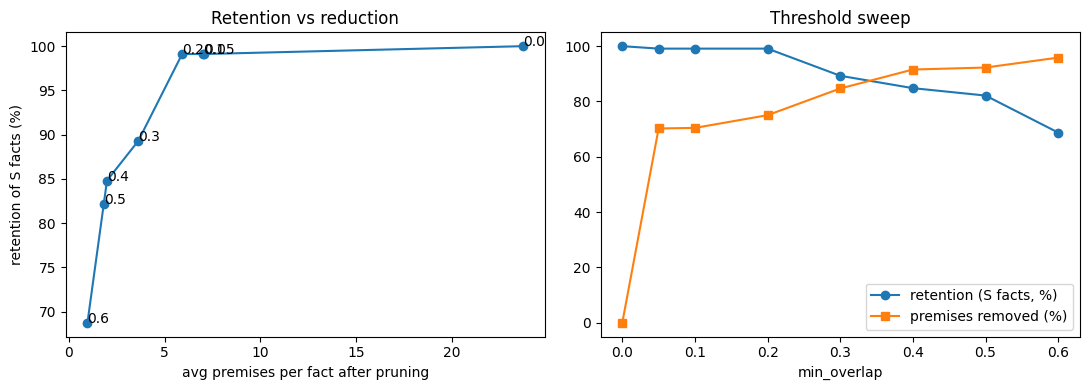

In [8]:
BASE_CFG = dict(splitter=BASE_SPLITTER, min_words=3, max_words=100)   # set from E1 / E2

def sentence_scores(exs, cfg):
    out = []
    for e in exs:
        ft = content_tokens(e.fact)
        out.append(np.array([overlap_score(ft, x['text']) for x in candidates(e.passages, cfg)]))
    return out

SC = sentence_scores(EXAMPLES, BASE_CFG)
is_S = np.array([e.label == 'S' for e in EXAMPLES])
total = np.array([len(s) for s in SC])

rows = []
for thr in [0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    kept = np.array([(s >= thr).sum() for s in SC])
    rows.append(dict(min_overlap=thr,
                     retention_S_pct=100 * np.mean(kept[is_S] > 0),
                     avg_premises_after=kept.mean(),
                     avg_premises_before=total.mean(),
                     pct_removed=100 * (1 - kept.sum() / total.sum()),
                     facts_needing_fallback_pct=100 * np.mean(kept == 0)))
E3 = pd.DataFrame(rows).round(2)
display(E3)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(E3.avg_premises_after, E3.retention_S_pct, 'o-')
for _, r in E3.iterrows(): ax[0].annotate(r.min_overlap, (r.avg_premises_after, r.retention_S_pct))
ax[0].set_xlabel('avg premises per fact after pruning'); ax[0].set_ylabel('retention of S facts (%)'); ax[0].set_title('Retention vs reduction')
ax[1].plot(E3.min_overlap, E3.retention_S_pct, 'o-', label='retention (S facts, %)')
ax[1].plot(E3.min_overlap, E3.pct_removed, 's-', label='premises removed (%)')
ax[1].set_xlabel('min_overlap'); ax[1].legend(); ax[1].set_title('Threshold sweep')
plt.tight_layout(); plt.show()

In [9]:
ok = E3[E3.retention_S_pct >= 97]
PRUNE_THR = float(ok.min_overlap.max()) if len(ok) else 0.0
BEST_CFG = dict(BASE_CFG)          # add window / title here after E6 / E7
print('PRUNE_THR =', PRUNE_THR, '| BEST_CFG =', BEST_CFG)

PRUNE_THR = 0.2 | BEST_CFG = {'splitter': 'regex', 'min_words': 3, 'max_words': 100}


In [10]:
rows = []
for w in [1, 2, 3, 10**6]:
    r = cov_stats(EXAMPLES, {**BEST_CFG, 'window': w})
    rows.append(dict(window='whole passage' if w == 10**6 else w, **r))
E6a = pd.DataFrame(rows).round(3)
display(E6a)

,window,premises_per_fact,words_per_premise,pct_over_128_words,coverage,seconds
0,1,23.719,18.525,0.000,0.691,0.131
1,2,20.860,37.117,0.195,0.745,0.168
2,3,18.158,55.046,0.548,0.767,0.186
3,whole passage,3.104,141.554,72.741,0.778,0.140
